# Insurance costs (v2)

<a href="https://colab.research.google.com/github/Aadharsh21/ML-Projects/blob/main/notebooks/03-insurance-costs.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Estimate a customer's yearly medical charges from age, sex, BMI, number of children, smoking and region.

The first version ([`notebooks/v1/LINEARINSURANCE.ipynb`](v1/LINEARINSURANCE.ipynb)) plotted BMI against charges,
spotted that smokers pay far more, and fit two straight lines on age alone, one for smokers and one for non-smokers.
This version finds the structure hiding in that plot, uses every column, and gives a range instead of a single
number.

| 5-fold cross-validation, repeated 5 times | R² | Mean absolute error |
|---|---|---|
| v1: age only, separate lines for smokers | 0.714 | $4,146 |
| Linear regression, all columns | 0.743 | $4,205 |
| LightGBM, all columns | 0.855 | $2,525 |
| **v2: linear regression with smoker x BMI interactions** | **0.865** | **$2,344** |

The middle-80% range it reports contained the real charge for 86% of held-out customers.
Code: [`ml/insurance.py`](../ml/insurance.py).

In [1]:
# Setup: runs from a local clone, or in Google Colab (it clones the repo first)
import os, sys
if "google.colab" in sys.modules:
    if not os.path.exists("ML-Projects"):
        !git clone -q https://github.com/Aadharsh21/ML-Projects.git
    %cd ML-Projects
    %pip install -q "lightgbm>=4.3"
elif os.path.basename(os.getcwd()) == "notebooks":
    os.chdir("..")
sys.path.insert(0, os.getcwd())

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from ml import data, insurance, plotting as P

P.style()
pd.set_option("display.precision", 1)

## 1. The data

1,338 US customers from the [Medical Cost Personal Datasets](https://www.kaggle.com/datasets/mirichoi0218/insurance)
(originally from *Machine Learning with R* by Brett Lantz). Charges are what the insurer paid out in a year, not the
premium.

In [3]:
df = data.load_insurance()
y = df["charges"].to_numpy()
smoker = df["smoker"] == "yes"
obese = df["bmi"] >= 30
group = np.select([~smoker, smoker & ~obese], ["Non-smoker", "Smoker, BMI under 30"], "Smoker, BMI 30+")
print(f"{len(df):,} customers, mean charges ${y.mean():,.0f}, median ${np.median(y):,.0f}")
pd.DataFrame({"customers": pd.Series(group).value_counts(),
              "mean charges": pd.Series(y).groupby(group).mean().round(0)})

1,338 customers, mean charges $13,270, median $9,382


,customers,mean charges
Non-smoker,1064,8434.0
"Smoker, BMI 30+",145,41558.0
"Smoker, BMI under 30",129,21363.0


The v1 notebook coloured its scatter by smoking only. Splitting smokers by BMI shows three separate bands: smokers
with a BMI of 30 or more (the clinical threshold for obesity) are charged about twice as much as other smokers.
Notice the blue dots scattered above the bottom band too: some non-smokers are charged far more than their age
predicts, which comes back in section 5.

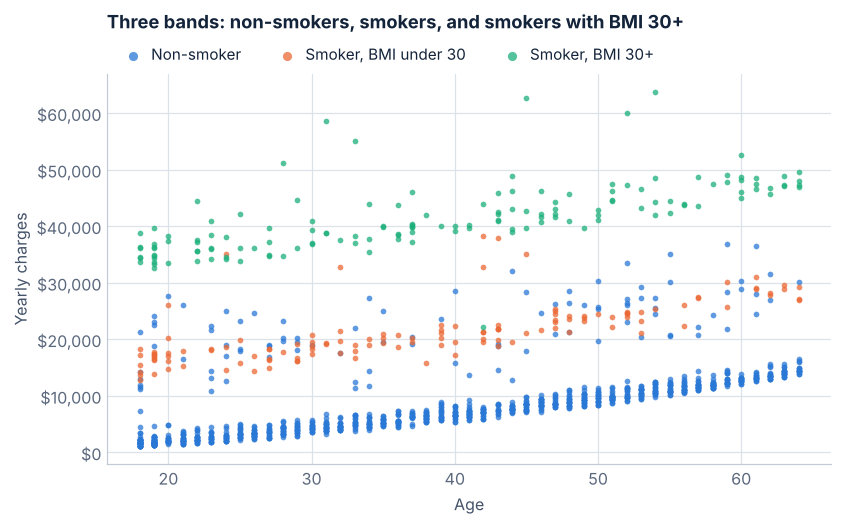

In [4]:
colors = {"Non-smoker": P.BLUE, "Smoker, BMI under 30": P.ORANGE, "Smoker, BMI 30+": P.AQUA}
fig, ax = plt.subplots(figsize=(8.5, 4.6))
for g, c in colors.items():
    mask = group == g
    ax.scatter(df.loc[mask, "age"], y[mask], s=14, color=c, alpha=0.75, lw=0, label=g)
ax.yaxis.set_major_formatter(plt.matplotlib.ticker.FuncFormatter(P.dollars))
ax.set_xlabel("Age")
ax.set_ylabel("Yearly charges")
ax.set_title("Three bands: non-smokers, smokers, and smokers with BMI 30+", pad=30)
ax.legend(loc="lower left", bbox_to_anchor=(0, 1.0), ncol=3, markerscale=1.6, borderaxespad=0.3, handletextpad=0.2)
P.save(fig, "insurance-bands.png")
plt.show()

## 2. v1, rebuilt

`AgeOnlyBySmoker` refits v1's two lines. It reproduces the predictions printed in the original notebook (a test
checks this to nine digits). Because v1 never sees BMI, its smoker line runs between the two smoker bands and is
wrong for nearly every smoker.

v1 smoker predictions at 23, 37, 54: [27314.59 31587.92 36776.96]


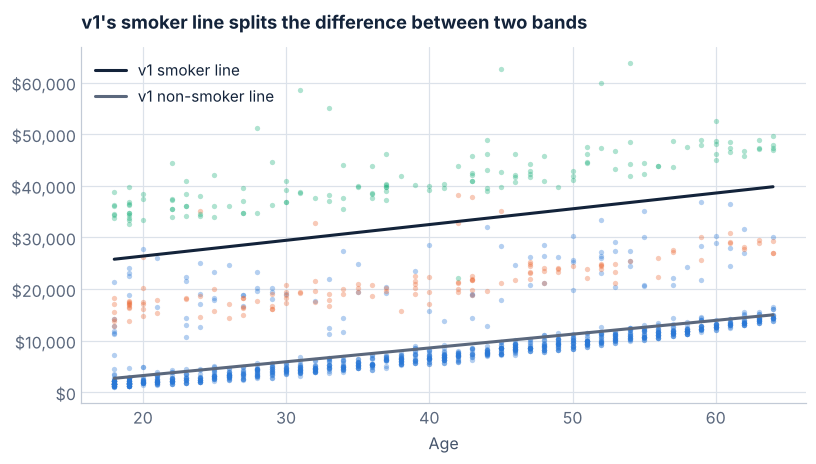

In [5]:
v1 = insurance.AgeOnlyBySmoker().fit(df, y)
ages = pd.DataFrame({"age": [23, 37, 54], "smoker": ["yes"] * 3})
print("v1 smoker predictions at 23, 37, 54:", np.round(v1.predict(ages), 2))

fig, ax = plt.subplots(figsize=(8.5, 4.2))
for g, c in colors.items():
    mask = group == g
    ax.scatter(df.loc[mask, "age"], y[mask], s=12, color=c, alpha=0.35, lw=0)
grid = np.arange(18, 65)
for s, c, label in [("yes", P.INK, "v1 smoker line"), ("no", P.INK_3, "v1 non-smoker line")]:
    ax.plot(grid, v1.predict(pd.DataFrame({"age": grid, "smoker": s})), color=c, label=label)
ax.yaxis.set_major_formatter(plt.matplotlib.ticker.FuncFormatter(P.dollars))
ax.set_xlabel("Age")
ax.set_title("v1's smoker line splits the difference between two bands")
ax.legend(loc="upper left")
plt.show()

## 3. v2: let the model see the bands

The design matrix (`insurance.design`) keeps every column and adds four terms:

- `obese`: BMI of 30 or more
- `smoker_obese`: the jump for smokers who are also obese
- `smoker_bmi`: smokers' charges also climb with BMI
- `age_squared`: charges rise a little faster with age

It is still a linear regression, so every coefficient reads in dollars:

In [6]:
model = insurance.Linear().fit(df, y)
coef = pd.Series(model.model.coef_, index=insurance.FEATURES)
pd.DataFrame({"dollars": coef.round(0)}).T

,age,age_squared,bmi,children,smoker,male,region_northwest,region_southeast,region_southwest,obese,smoker_obese,smoker_bmi
dollars,-24.0,4.0,15.0,677.0,848.0,-541.0,-390.0,-900.0,-1246.0,18.0,14822.0,495.0


In [7]:
example = pd.DataFrame({"age": [45, 45], "sex": ["male"] * 2, "bmi": [29.9, 30.0], "children": [1, 1],
                        "smoker": ["yes"] * 2, "region": ["southeast"] * 2})
a, b = model.predict(example)
print(f"A 45-year-old smoker at BMI 29.9: ${a:,.0f}.  At BMI 30.0: ${b:,.0f}.  A step of ${b - a:,.0f}.")

A 45-year-old smoker at BMI 29.9: $24,337.  At BMI 30.0: $39,229.  A step of $14,891.


## 4. Comparison under cross-validation

With only 1,338 rows a single train/test split is noisy, so each model is scored on 25 held-out folds (5-fold
cross-validation, repeated 5 times with different shuffles).

In [8]:
comparison = {label: insurance.cross_validate(df, y, factory) for label, factory in insurance.CANDIDATES.values()}
table = pd.DataFrame({
    label: {"R² mean": r["r2"]["mean"], "R² std": r["r2"]["std"], "MAE": r["mae"]["mean"], "RMSE": r["rmse"]["mean"]}
    for label, r in comparison.items()
}).T
table.style.format({"R² mean": "{:.3f}", "R² std": "{:.3f}", "MAE": "${:,.0f}", "RMSE": "${:,.0f}"})

,R² mean,R² std,MAE,RMSE
"v1: age only, separate lines for smokers",0.714,0.039,"$4,146","$6,417"
"Linear regression, all columns",0.743,0.040,"$4,205","$6,080"
"LightGBM, all columns",0.855,0.034,"$2,525","$4,536"
v2: linear regression with smoker x BMI interactions,0.865,0.033,"$2,344","$4,381"


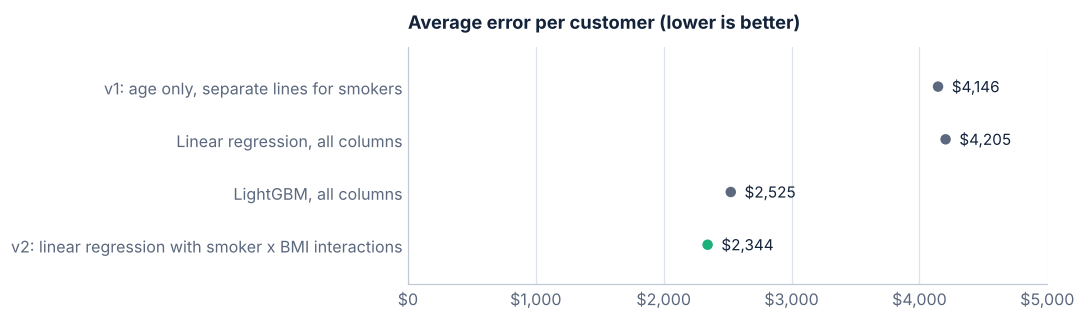

In [9]:
fig, ax = plt.subplots(figsize=(7.5, 2.8))
names = list(table.index)
mae = table["MAE"].to_numpy()
cols = [P.AQUA if n.startswith("v2") else P.INK_3 for n in names]
ax.scatter(mae, names, s=70, color=cols, ec="white", lw=1.5, zorder=3)
for v, n in zip(mae, names):
    ax.annotate(P.dollars(v), (v, n), xytext=(9, 0), textcoords="offset points", va="center", fontsize=10)
ax.set_xlim(0, 5000)
ax.margins(y=0.25)
ax.xaxis.set_major_formatter(plt.matplotlib.ticker.FuncFormatter(P.dollars))
ax.invert_yaxis()
ax.grid(axis="y", visible=False)
ax.set_title("Average error per customer (lower is better)")
P.save(fig, "insurance-models.png")
plt.show()

Adding columns to a straight line barely helps (the error even rises a little): the model needs the interaction.
LightGBM finds it on its own and gets close, but the hand-built linear model wins and stays explainable, so it is
the one that ships.

## 5. What the model can't see

Out-of-fold residuals (each customer predicted by a model that never saw them) are lopsided: most customers sit just
under their prediction, and about 9% of non-smokers are charged $5,000 or more above it. Nothing in the data
explains who; it is most likely a health condition the dataset doesn't record.

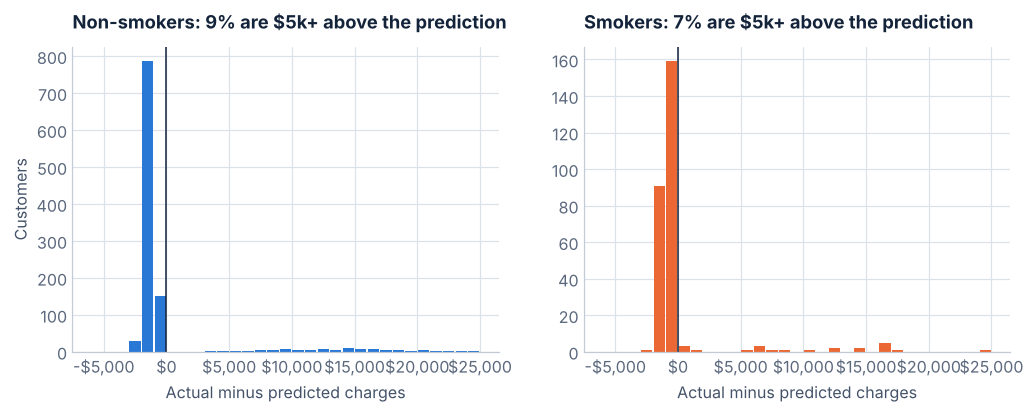

In [10]:
residuals = insurance.out_of_fold_residuals(df, y)
fig, axes = plt.subplots(1, 2, figsize=(11, 3.6), sharey=False)
for ax, (label, mask, c) in zip(axes, [("Non-smokers", ~smoker, P.BLUE), ("Smokers", smoker, P.ORANGE)]):
    ax.hist(residuals[mask], bins=np.arange(-6000, 26000, 1000), color=c, rwidth=0.9)
    ax.axvline(0, color=P.INK, lw=1)
    share = (residuals[mask] > 5000).mean()
    ax.set_title(f"{label}: {share:.0%} are $5k+ above the prediction")
    ax.xaxis.set_major_formatter(plt.matplotlib.ticker.FuncFormatter(P.dollars))
    ax.set_xlabel("Actual minus predicted charges")
axes[0].set_ylabel("Customers")
plt.show()

## 6. A range, not just a number

Because the errors are lopsided, a symmetric "plus or minus" would be misleading. Instead the model adds the 10th,
50th and 90th percentile of the out-of-fold residuals (separately for smokers and non-smokers) to its prediction.
On held-out customers that range should contain the real charge about 80% of the time; checked over 100 random
splits, it does slightly better.

The lopsidedness has a striking consequence: the regression's prediction is an *average*, and for most people the
*typical* charge (the median) is lower than that, sometimes below the whole 80% range, because the average carries
the minority with much higher bills. A calculator should lead with the typical value and show the average second.

In [11]:
coverage = insurance.interval_coverage(df, y, repeats=100)
print(f"Middle-80% range contained the real charge for {coverage['coverage']:.1%} of held-out customers "
      f"(average width ${coverage['mean_width']:,.0f})")

pools = insurance.residual_pools(df, residuals)
person = pd.DataFrame({"age": [33], "sex": ["female"], "bmi": [31.5], "children": [2], "smoker": ["no"],
                       "region": ["northwest"]})
pred = model.predict(person)[0]
lo, mid, hi = pred + np.quantile(pools["non_smoker"], [0.1, 0.5, 0.9])
print(f"33-year-old non-smoker, BMI 31.5, two children:")
print(f"  typical charges ${mid:,.0f}; 8 in 10 people like her pay ${lo:,.0f} to ${hi:,.0f}")
print(f"  average ${pred:,.0f}, above the whole range, pulled up by the 1 in 11 who pay far more")

Middle-80% range contained the real charge for 86.0% of held-out customers (average width $1,563)
33-year-old non-smoker, BMI 31.5, two children:
  typical charges $6,001; 8 in 10 people like her pay $5,555 to $6,766
  average $7,342, above the whole range, pulled up by the 1 in 11 who pay far more


## 7. Why this customer's estimate is what it is

Exact Shapley values over the six inputs: how much each one moves the estimate away from the average customer
($13,270). With six inputs there are only 64 combinations to evaluate, so no approximation is needed.

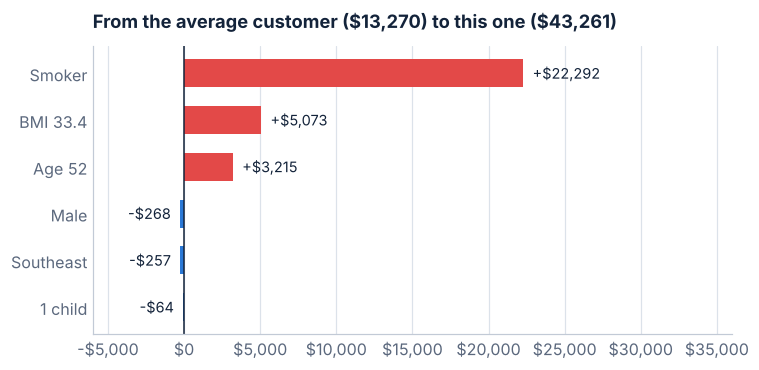

In [12]:
background = insurance.encode_inputs(df)
x = np.array([52, 1, 33.4, 1, 1, 2], dtype=float)  # 52, male, BMI 33.4, one child, smoker, southeast
phi, base = insurance.shapley(model, x, background)
labels = ["Age 52", "Male", "BMI 33.4", "1 child", "Smoker", "Southeast"]
order = np.argsort(np.abs(phi))
fig, ax = plt.subplots(figsize=(7.5, 3.4))
ax.barh(np.array(labels)[order], phi[order], color=[P.RED if v > 0 else P.BLUE for v in phi[order]], height=0.6)
for v, l in zip(phi[order], np.array(labels)[order]):
    ax.annotate(P.dollars(v) if v < 0 else "+" + P.dollars(v), (v, l), xytext=(6 if v >= 0 else -6, 0),
                textcoords="offset points", va="center", ha="left" if v >= 0 else "right", fontsize=9.5)
ax.axvline(0, color=P.INK, lw=1)
ax.xaxis.set_major_formatter(plt.matplotlib.ticker.FuncFormatter(P.dollars))
ax.grid(axis="y", visible=False)
ax.set_xlim(-6000, 36000)
ax.set_title(f"From the average customer (${base:,.0f}) to this one (${base + phi.sum():,.0f})")
plt.show()

## 8. Export for the browser

`python -m ml insurance` writes the coefficients, the residual pools and all 1,338 customers (used as the Shapley
baseline) to `web/public/data/insurance/`, so a web calculator can show the estimate, the range and the breakdown
for any profile instantly.

## Limitations

- **Small and synthetic-feeling data.** 1,338 rows from a textbook dataset; no claims history, conditions or plan
  details, which is why about one in twelve customers sits far above any prediction.
- **Charges, not premiums.** This estimates what was paid out, not what anyone would be quoted.
- **Sensitive inputs.** Sex and region are in the data and in the model. Their effects are small next to smoking (all under
  $1,300), but a real pricing model would need a fairness review of any protected attribute.